In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\thewr\AppData\Local\Temp\ipykernel_41492\3432078421.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\thewr\git\LSTM_giroscopio_acelerometro.git\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('activity_recognition_data.csv')

In [4]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [5]:
data.isnull().sum()

pessoa_x          0
atividade         0
tempo             0
acelerômetro_x    0
acelerômetro_Y    0
acelerômetro_Z    0
giroscópio_x      0
giroscópio_Y      0
giroscópio_Z      0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

In [7]:
data.columns

Index(['pessoa_x', 'atividade', 'tempo', 'acelerômetro_x', 'acelerômetro_Y',
       'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z'],
      dtype='object')

In [8]:
data = data[['pessoa_x', 'atividade', 'tempo', 'acelerômetro_x', 'acelerômetro_Y',
       'acelerômetro_Z']]

# **Data Exploration**

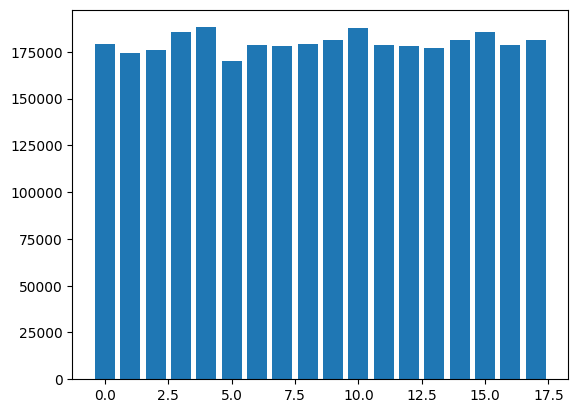

In [9]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

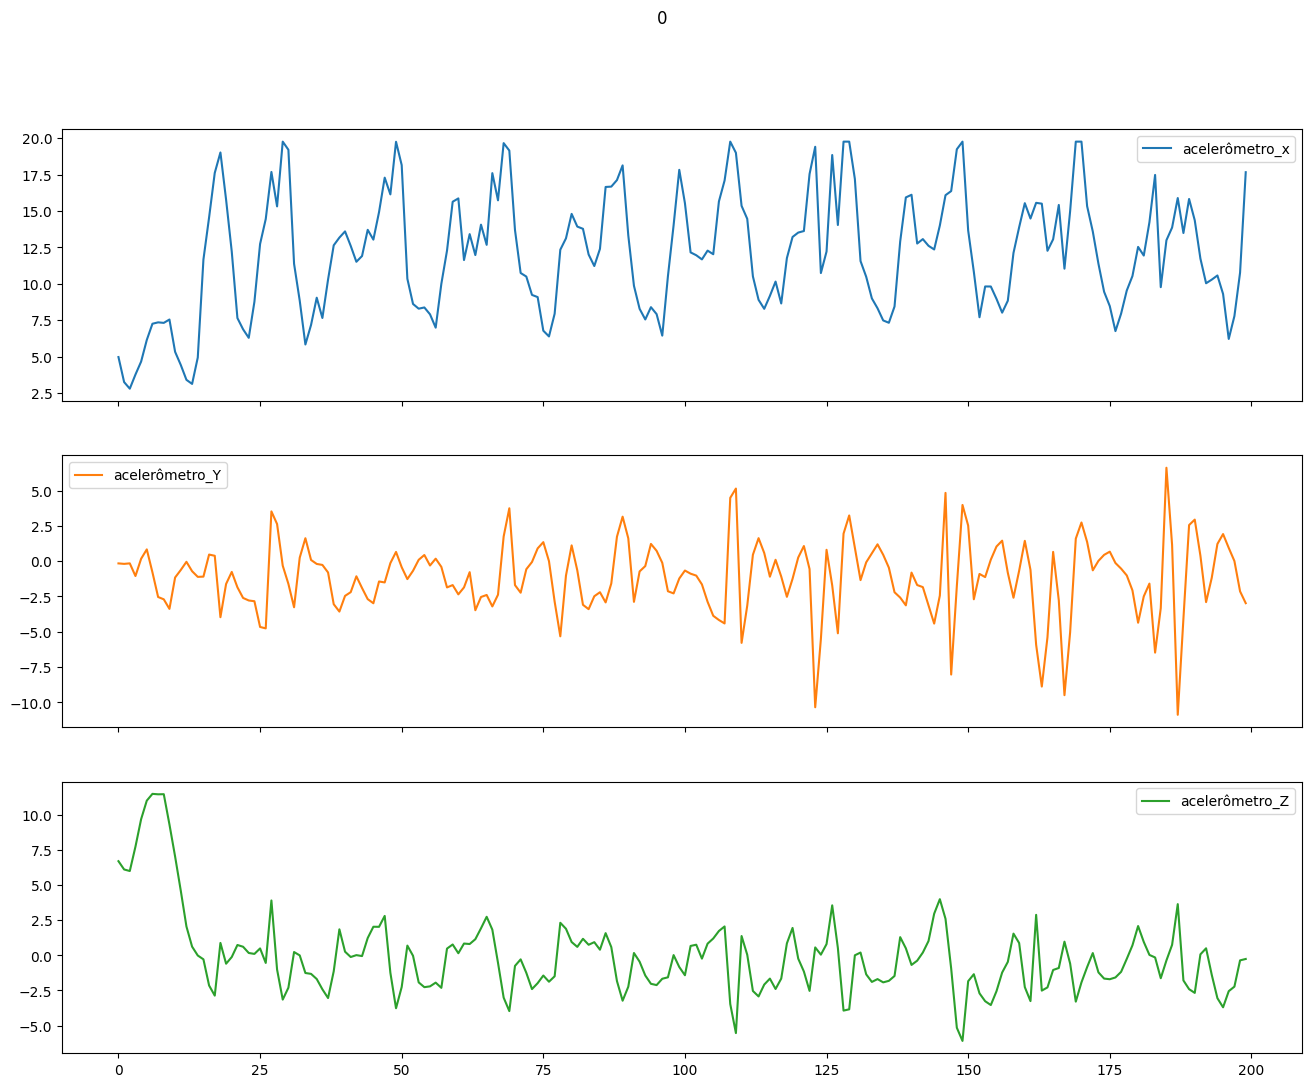

In [10]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

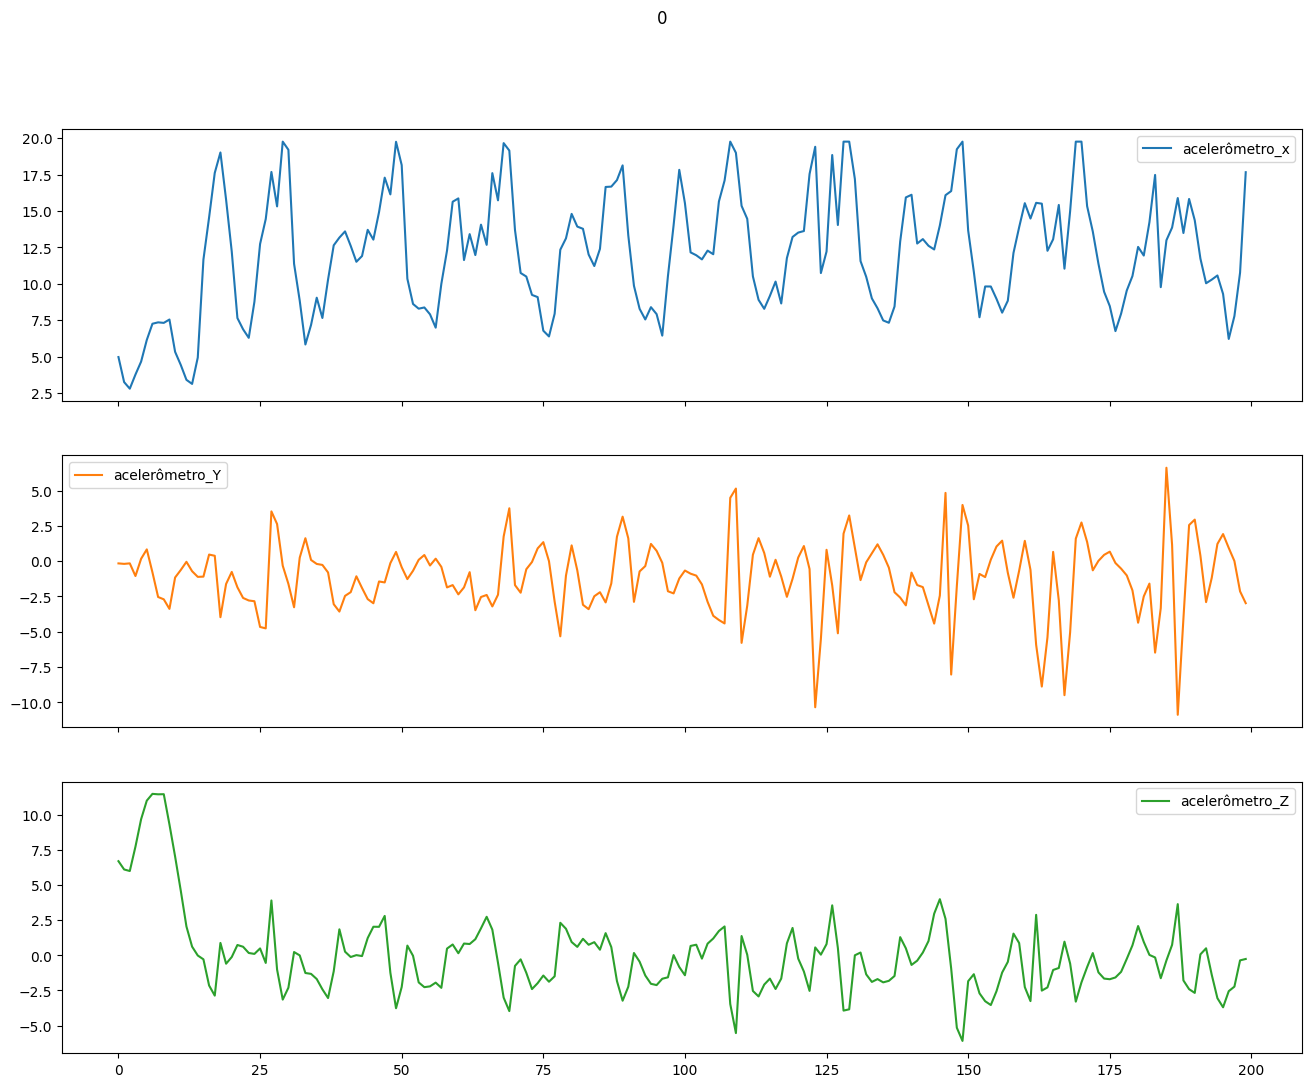

In [11]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

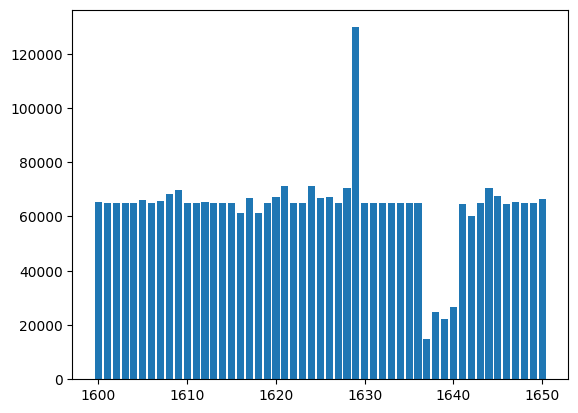

In [12]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [13]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [14]:
data.shape

(714799, 6)

In [15]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732
1,1600,0,90426807196641,3.253720,-0.191835,6.107758
2,1600,0,90426856696641,2.801216,-0.155922,5.997625
3,1600,0,90426906196641,3.770868,-1.051354,7.731027
4,1600,0,90426955696641,4.661511,0.169689,9.684695


In [16]:
data = data.reset_index()

In [17]:
data.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695


# **Models**

In [18]:
index_split_test_and_validation_train = data[(data['pessoa_x'].isin([1600,1601,1602,1603,1604]))].tail(1).index[0]
print(index_split_test_and_validation_train)

72054


In [19]:
#Will be used in model training and validation (approx. 90%)
train_validation_indices = []
#Will be used in final test of the model after training (approx. 10%)
test_indices = []


train_validation_indices.extend(data.index[index_split_test_and_validation_train+1:])
test_indices.extend(data.index[:index_split_test_and_validation_train+1])

# Split the dataset without shuffling
print(len(train_validation_indices))
print(len(test_indices))
X_train_validation = data.iloc[train_validation_indices]
X_test = data.iloc[test_indices]


# Print shapes to verify proportions
print("Train/validation set:", X_train_validation.shape)
print("Test set:", X_test.shape)

642744
72055
Train/validation set: (642744, 7)
Test set: (72055, 7)


In [20]:
X_test.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695


In [21]:
X_test.tail()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
72050,274471,1604,3,693286335637628,0.324265,5.887641,7.825598
72051,274472,1604,3,693286385566718,0.362572,6.146215,7.746589
72052,274473,1604,3,693286435495808,0.309899,5.978621,7.722647
72053,274474,1604,3,693286485424898,0.386514,6.162974,7.713070
72054,274475,1604,3,693286535353988,0.333842,6.115090,7.693917


In [22]:
X_train_validation.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
72055,324933,1605,0,9914136743005,6.753594,-4.764910,0.682347
72056,324934,1605,0,9914186746890,7.301866,-4.116082,0.744597
72057,324935,1605,0,9914236752414,7.610718,-3.840749,1.113304
72058,324936,1605,0,9914286674776,8.999355,-3.986795,1.070208
72059,324937,1605,0,9914336690902,10.996120,-3.754557,0.720655


In [23]:
X_train_validation.tail()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
714794,3188405,1650,3,2425320732993807,-0.791733,0.860416,9.715521
714795,3188406,1650,3,2425320782976267,-0.784550,0.908300,9.717916
714796,3188407,1650,3,2425320832958727,-0.794127,0.819715,9.679607
714797,3188408,1650,3,2425320882941187,-0.827646,0.905906,9.765799
714798,3188409,1650,3,2425320932928957,-0.844405,0.764648,9.737069


In [24]:
X_test = X_test.reset_index(drop=True)

In [25]:
X_test = X_test.drop('index',axis=1)


In [26]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72055 entries, 0 to 72054
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pessoa_x        72055 non-null  int64  
 1   atividade       72055 non-null  int64  
 2   tempo           72055 non-null  int64  
 3   acelerômetro_x  72055 non-null  float64
 4   acelerômetro_Y  72055 non-null  float64
 5   acelerômetro_Z  72055 non-null  float64
dtypes: float64(3), int64(3)
memory usage: 3.3 MB


In [27]:
X_test['atividade'].value_counts()

atividade
1    18014
2    18014
3    18014
0    18013
Name: count, dtype: int64

In [28]:
X_test = X_test[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z','atividade']]

In [29]:
print(X_test.shape)

(72055, 4)


In [30]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [31]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [32]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [33]:
segments_test,targets_test = apply_segmentation_no_sliding_window(X_test)

In [34]:
print(segments_test.shape)
print(targets_test.shape)

(360, 200, 3)
(360, 200, 1)


In [35]:
segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)

In [36]:
print(segments_test.shape)
print(targets_test.shape)

(341, 200, 3)
(341, 200, 1)


In [37]:
print(segments_test.shape[0])

341


In [38]:
targets_test = targets_test.reshape(targets_test.shape[0],200)

In [39]:
print(targets_test.shape)

(341, 200)


In [40]:
labels_test = targets_test[:,0]

In [41]:
print(labels_test.shape)

(341,)


In [42]:
labels_test_categorical = to_categorical(labels_test,num_classes=4)

In [43]:
print(labels_test_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [44]:
print(labels_test_categorical.shape)

(341, 4)


In [45]:
X_train_validation = X_train_validation.reset_index(drop=True)
X_train_validation = X_train_validation.drop('index',axis=1)

In [46]:
X_train_validation.shape

(642744, 6)

In [47]:
X_train_validation.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
0,1605,0,9914136743005,6.753594,-4.764910,0.682347
1,1605,0,9914186746890,7.301866,-4.116082,0.744597
2,1605,0,9914236752414,7.610718,-3.840749,1.113304
3,1605,0,9914286674776,8.999355,-3.986795,1.070208
4,1605,0,9914336690902,10.996120,-3.754557,0.720655


In [48]:
X_train_validation.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
642739,1650,3,2425320732993807,-0.791733,0.860416,9.715521
642740,1650,3,2425320782976267,-0.784550,0.908300,9.717916
642741,1650,3,2425320832958727,-0.794127,0.819715,9.679607
642742,1650,3,2425320882941187,-0.827646,0.905906,9.765799
642743,1650,3,2425320932928957,-0.844405,0.764648,9.737069


In [49]:
index_train_validation_split = X_train_validation.loc[(X_train_validation['pessoa_x'] == 1614) & (X_train_validation['atividade'] == 3)].tail(1).index[0]

In [50]:
print(index_train_validation_split)

144113


In [51]:
X_validation_data = X_train_validation[:index_train_validation_split+1]

In [52]:
X_validation_data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
0,1605,0,9914136743005,6.753594,-4.764910,0.682347
1,1605,0,9914186746890,7.301866,-4.116082,0.744597
2,1605,0,9914236752414,7.610718,-3.840749,1.113304
3,1605,0,9914286674776,8.999355,-3.986795,1.070208
4,1605,0,9914336690902,10.996120,-3.754557,0.720655


In [53]:
X_validation_data.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
144109,1614,3,84284633584665,5.235221,-4.745757,7.050176
144110,1614,3,84284683545765,5.220856,-4.745757,6.793996
144111,1614,3,84284733506865,5.139453,-4.812794,6.592883
144112,1614,3,84284783467965,5.352537,-5.073762,6.722170
144113,1614,3,84284833429065,5.479430,-4.966023,6.918495


In [54]:
X_validation_data.shape

(144114, 6)

In [55]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z','atividade']]

In [56]:
segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(7196, 200, 1)
(7196, 200, 3)


In [57]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(6807, 200, 1)
(6807, 200, 3)


In [58]:
targets_val = targets_val.reshape(targets_val.shape[0],200)

In [59]:
print(targets_val.shape)

(6807, 200)


In [60]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]


In [61]:
labels_val = targets_val[:,0]

In [62]:
print(labels_val)

[0 0 0 ... 3 3 3]


In [63]:
print(labels_val.shape)

(6807,)


In [64]:
labels_val_categorical = to_categorical(labels_val,num_classes=4)

In [65]:
print(labels_val_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [66]:
print(labels_val_categorical.shape)

(6807, 4)


In [67]:
X_train_data = X_train_validation[index_train_validation_split+1:]

In [68]:
X_train_data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
144114,1615,0,80004323849486,7.931840,-1.045219,-2.230199
144115,1615,0,80004373349486,6.737134,-10.686669,1.425747
144116,1615,0,80004422849486,2.834585,1.487847,-2.479196
144117,1615,0,80004472349486,7.105841,-1.389984,1.528698
144118,1615,0,80004521849486,8.757840,-5.833622,1.820790


In [69]:
X_train_data.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z
642739,1650,3,2425320732993807,-0.791733,0.860416,9.715521
642740,1650,3,2425320782976267,-0.784550,0.908300,9.717916
642741,1650,3,2425320832958727,-0.794127,0.819715,9.679607
642742,1650,3,2425320882941187,-0.827646,0.905906,9.765799
642743,1650,3,2425320932928957,-0.844405,0.764648,9.737069


In [70]:
X_train_data.shape

(498630, 6)

In [71]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z','atividade']]

In [72]:
segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)

In [73]:
print(segments_train.shape)
print(targets_train.shape)

(24922, 200, 3)
(24922, 200, 1)


In [74]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [75]:
print(segments_train.shape)
print(targets_train.shape)

(23565, 200, 3)
(23565, 200, 1)


In [76]:
targets_train = targets_train.reshape(targets_train.shape[0],200)

In [77]:
print(targets_train.shape)

(23565, 200)


In [78]:
labels_train = targets_train[:,0]

In [79]:
labels_train_categorical = to_categorical(labels_train,num_classes=4)

In [80]:
print(labels_train_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [81]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [82]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(23565, 200, 3)
(23565, 4)
(6807, 200, 3)
(6807, 4)


In [83]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [84]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [85]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(23565, 200, 3)
(23565, 4)
(6807, 200, 3)
(6807, 4)


In [86]:
#from tensorflow.keras import regularizers

In [87]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [88]:
def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')), input_shape=(200,3), return_sequences=False))  
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model


In [89]:
tuner = RandomSearch(
    cria_LSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 3,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [90]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [91]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 3 Complete [00h 30m 56s]
val_accuracy: 0.961950957775116

Best val_accuracy So Far: 0.961950957775116
Total elapsed time: 02h 19m 25s


In [92]:
tuner.results_summary()

Results summary
Results in C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Code/DataPrep/2024-02-18_08-05-07\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
input_units: 128
l2_reg: 0.0005377164071193433
input_units_relu: 256
learning_rate: 0.001715074355925934
Score: 0.961950957775116

Trial 0 summary
Hyperparameters:
input_units: 192
l2_reg: 0.00013051352453616747
input_units_relu: 128
learning_rate: 0.0003497444477863496
Score: 0.9425591230392456

Trial 1 summary
Hyperparameters:
input_units: 256
l2_reg: 0.001136419736136108
input_units_relu: 160
learning_rate: 0.00013607174450468629
Score: 0.8998090028762817


In [93]:
tuner.get_best_hyperparameters()[0].values

{'input_units': 128,
 'l2_reg': 0.0005377164071193433,
 'input_units_relu': 256,
 'learning_rate': 0.001715074355925934}

In [94]:
best_model = tuner.get_best_models(num_models=1)[0]

In [95]:
best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 128)               67584     
                                                                 
 dense (Dense)               (None, 256)               33024     
                                                                 
 dense_1 (Dense)             (None, 4)                 1028      
                                                                 
Total params: 101636 (397.02 KB)
Trainable params: 101636 (397.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [96]:
X_test.shape

(72055, 4)

In [97]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

213/213 [==============================] - 14s 60ms/step - loss: 0.2060 - accuracy: 0.9620


In [98]:
predictions = best_model.predict(X_validation)

213/213 [==============================] - 13s 58ms/step


In [99]:
print(y_validation)

[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]


In [100]:
print(y_validation.shape)

(6807, 4)


In [101]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [102]:
print(y_validation_inverse)

[3 1 0 ... 1 1 3]


In [103]:
print(len(y_validation_inverse))

6807


In [104]:
print(predictions)

[[1.9594331e-03 6.4964665e-06 4.4279618e-06 9.9802953e-01]
 [1.8270667e-08 9.9999928e-01 6.9912926e-07 3.4316027e-08]
 [9.9760890e-01 3.7077466e-06 3.3804993e-04 2.0493309e-03]
 ...
 [1.0919206e-07 9.9999774e-01 1.4231970e-06 6.6583010e-07]
 [9.3912497e-08 9.9999440e-01 5.0777212e-06 4.2880981e-07]
 [1.4339895e-07 1.7389753e-09 5.6184970e-08 9.9999976e-01]]


In [105]:
classes_x=np.argmax(predictions,axis=1)

In [106]:
print(classes_x)

[3 1 0 ... 1 1 3]


In [107]:
print(len(classes_x))

6807


In [108]:
print(classes_x.shape)

(6807,)


In [109]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [110]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

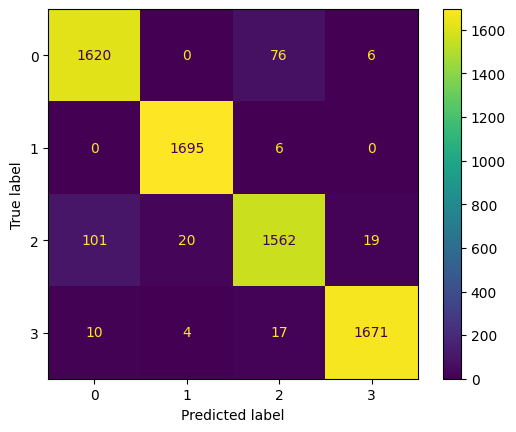

In [111]:
disp.plot()

In [112]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.94      0.95      0.94      1702
           1       0.99      1.00      0.99      1701
           2       0.94      0.92      0.93      1702
           3       0.99      0.98      0.98      1702

    accuracy                           0.96      6807
   macro avg       0.96      0.96      0.96      6807
weighted avg       0.96      0.96      0.96      6807



In [113]:
print(segments_test)

[[[ 4.9727569e+00 -1.5831658e-01  6.6967316e+00]
  [ 3.2537200e+00 -1.9183542e-01  6.1077580e+00]
  [ 2.8012159e+00 -1.5592238e-01  5.9976249e+00]
  ...
  [ 7.7835498e+00  9.2775319e-03 -2.2264578e+00]
  [ 1.0766725e+01 -2.1359272e+00 -3.5898063e-01]
  [ 1.7662025e+01 -2.9738977e+00 -2.5842413e-01]]

 [[ 1.5133749e+01 -3.2683847e+00 -2.5602993e-01]
  [ 9.2176762e+00 -8.0475104e-01 -8.7133980e-01]
  [ 8.8896713e+00 -2.4211365e-01  1.5098435e-01]
  ...
  [ 1.2543222e+01 -7.1616560e-01 -8.4021515e-01]
  [ 1.0584765e+01  1.7809868e+00 -2.8537388e+00]
  [ 9.7491894e+00  1.6947955e+00 -2.9638720e+00]]

 [[ 1.5550340e+01 -1.7552491e+00  3.9279872e-01]
  [ 1.5334862e+01 -2.5884314e+00  9.8416656e-01]
  [ 1.4607024e+01 -1.3626001e+00  9.5917709e-02]
  ...
  [ 8.6382799e+00 -5.1744682e-01 -1.8420389e-01]
  [ 8.1809874e+00  2.0560206e-01 -1.0652701e+00]
  [ 8.8872766e+00  3.5613749e-02 -1.0245687e+00]]

 ...

 [[ 3.1805472e+00 -3.6197338e+00  8.6228666e+00]
  [ 3.1829414e+00 -3.6101568e+00  8.560

In [114]:
print(labels_test_categorical.shape)

(341, 4)


In [115]:
print(labels_test_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [116]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

11/11 [==============================] - 1s 87ms/step - loss: 0.9057 - accuracy: 0.8240


In [117]:
predictions_test = best_model.predict(segments_test)

11/11 [==============================] - 1s 59ms/step


In [118]:
print(predictions_test)

[[1.6998103e-03 2.6660779e-05 9.9772245e-01 5.5100169e-04]
 [9.9544048e-01 1.1405908e-07 3.5183772e-03 1.0410529e-03]
 [9.9555773e-01 1.4066288e-07 2.5253585e-03 1.9167772e-03]
 ...
 [1.6656537e-07 1.8986277e-09 6.6714307e-08 9.9999976e-01]
 [1.8422185e-07 2.2976379e-09 9.0696936e-08 9.9999976e-01]
 [4.9872510e-04 9.5574308e-07 9.3655999e-06 9.9949098e-01]]


In [119]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [120]:
print(classes_x_test)

[2 0 0 2 0 2 0 2 2 0 2 2 2 0 2 2 0 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 2 0 0 2 2 0 2 0 2 0
 2 2 2 2 2 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 3 0 2 2 2 2 3 2 2 2 2 2
 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3]


In [121]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [122]:
print(labels_test_argmax)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3]


In [123]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

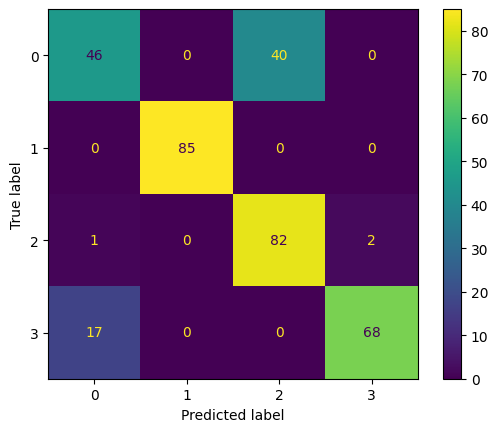

In [124]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [125]:
print(classification_report(labels_test_argmax, classes_x_test))

              precision    recall  f1-score   support

           0       0.72      0.53      0.61        86
           1       1.00      1.00      1.00        85
           2       0.67      0.96      0.79        85
           3       0.97      0.80      0.88        85

    accuracy                           0.82       341
   macro avg       0.84      0.82      0.82       341
weighted avg       0.84      0.82      0.82       341



In [126]:
best_model.save(WORKDIR+"/Model/best_models_saved")

INFO:tensorflow:Assets written to: C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Model/best_models_saved\assets


INFO:tensorflow:Assets written to: C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Model/best_models_saved\assets
